# Quantum Rock, Paper, Scissors
**Qiskit Fall Fest Nairobi 2026 – Challenge 07** · by Ian Kamau

## What I built
A Rock, Paper, Scissors game where the computer's choice comes from measuring qubits instead of a classical random number generator.

## The problem
Two qubits give 4 possible results (`00`, `01`, `10`, `11`), but the game only has 3 choices:
Rock = `00`, Paper = `01`, Scissors = `10`. So what do we do with `11`?

## What's in this notebook
1. Warm-up: a 1-qubit coin flip
2. Two qubits → four equally likely results
3. Approach 1 – treat `11` as Rock (unfair!)
4. Approach 2 – throw away `11` and measure again (fair, but wastes ~25% of runs)
5. Approach 3 – a custom circuit using `Ry` + controlled-H that never produces `11` (fair, nothing wasted)
6. The game – one round, then a full game with score and history
7. Testing on a simulated noisy IBM quantum computer, then on a real one (ibm_fez)
8. Comparing all approaches + conclusions

## 1. Warm-up: a 1-qubit quantum coin
The **H (Hadamard) gate** puts a qubit into **superposition**: an equal mix of `0` and `1`. When we **measure**, it becomes `0` or `1` with a 50% chance each.

**Result (100 shots):** 59 × `0`, 41 × `1`. Not exactly 50/50: with only 100 shots, random variation is normal, just like flipping a real coin 100 times.

In [15]:
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler

qc = QuantumCircuit(1)
qc.h(0)
qc.measure_all()
print(StatevectorSampler().run([qc], shots=100).result()[0].data.meas.get_counts())

{'0': 59, '1': 41}


## 2. Two qubits → four results
With an H gate on each of 2 qubits, there are 2² = 4 equally likely results: `00`, `01`, `10`, `11` (~25% each).

**Result (1,000 shots):** each appeared ~250 times. But the game only needs 3 choices, so `11` has no meaning, and about 1 in 4 runs is unusable.

In [2]:
qc = QuantumCircuit(2)   # 2 qubits this time
qc.h(0)                  # superposition on qubit 0
qc.h(1)                  # superposition on qubit 1
qc.measure_all()
print(qc.draw())

counts = StatevectorSampler().run([qc], shots=1000).result()[0].data.meas.get_counts()
print(counts)

        ┌───┐ ░ ┌─┐   
   q_0: ┤ H ├─░─┤M├───
        ├───┤ ░ └╥┘┌─┐
   q_1: ┤ H ├─░──╫─┤M├
        └───┘ ░  ║ └╥┘
meas: 2/═════════╩══╩═
                 0  1 
{'11': 262, '01': 260, '10': 220, '00': 258}


## 3. Approach 1: treat `11` as Rock (the naive fix)
**Result (10,000 shots):** Rock 48.9%, Paper 25.2%, Scissors 25.9%.

Rock comes up ~50% of the time because **two** results (`00` and `11`) both mean Rock. A player who notices this can always pick **Paper** and win about half their games. ❌ **Unfair.**

In [3]:
shots = 10000
naive_map = {'00': 'Rock', '01': 'Paper', '10': 'Scissors', '11': 'Rock'}  # naive: 11 also means Rock

counts = StatevectorSampler().run([qc], shots=shots).result()[0].data.meas.get_counts()

tally = {'Rock': 0, 'Paper': 0, 'Scissors': 0}
for bits, n in counts.items():
    tally[naive_map[bits]] += n

for choice, n in tally.items():
    print(f"{choice}: {n} times ({100 * n / shots:.1f}%)")

Rock: 4890 times (48.9%)
Paper: 2524 times (25.2%)
Scissors: 2586 times (25.9%)


## 4. Approach 2: throw away `11` and measure again
`get_bitstrings()` gives every result in order, like a list of rounds. Skipping every `11` and using the next result is the same as measuring again.

**Result:** Rock 33.1%, Paper 33.3%, Scissors 33.6%. ✅ Fair, but **2,547 of 10,000 runs (~25%) were wasted**. In the first 10 results, `11` came up 4 times, so a single round can need several retries.

In [4]:
choice_map = {'00': 'Rock', '01': 'Paper', '10': 'Scissors'}  # no 11 this time

results = StatevectorSampler().run([qc], shots=shots).result()[0].data.meas.get_bitstrings()
print(results[:10])   # peek at the first 10 individual results

kept = [bits for bits in results if bits != '11']   # throw away every 11 = "try again"

tally = {'Rock': 0, 'Paper': 0, 'Scissors': 0}
for bits in kept:
    tally[choice_map[bits]] += 1

for choice, n in tally.items():
    print(f"{choice}: {n} times ({100 * n / len(kept):.1f}%)")
print(f"Wasted runs (got 11): {shots - len(kept)} out of {shots}")

['11', '10', '00', '01', '11', '11', '00', '11', '10', '01']
Rock: 2466 times (33.1%)
Paper: 2485 times (33.3%)
Scissors: 2502 times (33.6%)
Wasted runs (got 11): 2547 out of 10000


## 5. Approach 3: a circuit that never produces `11`

Rather than correcting invalid outcomes after measurement, I built a quantum circuit in which the outcome `11` is impossible.

1. **Apply `Ry(θ)` to qubit 0.** Unlike a Hadamard gate, `Ry(θ)` allows an adjustable probability distribution. Starting from $|0\rangle$:

   $$P(q_0=0)=\cos^2(\theta/2), \qquad P(q_0=1)=\sin^2(\theta/2)$$

   Setting $P(q_0=0)=2/3$ gives:

   $$\theta=2\arccos\left(\sqrt{\frac{2}{3}}\right)\approx 1.231\text{ rad}\;(70.53^\circ)$$

   Consequently, qubit 0 is measured as `0` with probability $2/3$ and `1` with probability $1/3$.

2. **Apply a controlled-H gate to qubit 1, conditioned on qubit 0 being `0`.** In Qiskit, `ctrl_state=0` specifies this control condition, represented by a hollow control symbol in the circuit diagram.

### Outcome Mapping

Qiskit displays a two-bit measurement string as `c1c0`, with classical bit `c0` on the right. `measure_all()` measures qubit 0 into `c0` and qubit 1 into `c1`, so the outcomes map to the game as follows:

| Measurement | Qubit values `(q0, q1)` | Probability | Move |
|:---:|:---:|:---:|:---|
| `00` | `(0, 0)` | $1/3$ | Rock |
| `01` | `(1, 0)` | $1/3$ | Paper |
| `10` | `(0, 1)` | $1/3$ | Scissors |
| `11` | `(1, 1)` | $0$ | Impossible |

When qubit 0 is `1`, the controlled-H gate does not activate, so the circuit produces `01` (Paper). When qubit 0 is `0`, the Hadamard operation on qubit 1 splits the probability equally between `00` (Rock) and `10` (Scissors).

### Results

The ideal measurement probabilities are exactly $1/3$ for each move, with $P(11)=0$. In a 10,000-shot run, the observed distribution was:

- **Rock:** 33.1%
- **Paper:** 33.9%
- **Scissors:** 33.0%
- **Invalid outcome `11`:** 0%

The measured percentages fluctuate because of finite-shot sampling, but the circuit's ideal distribution is uniform.

**All measurement outcomes are valid, so no shots are discarded or corrected.**

In [ ]:
import numpy as np
from qiskit.quantum_info import Statevector

theta = 2 * np.arccos(np.sqrt(2/3))   # the angle that gives qubit 0 a 2/3 chance of being 0

qc3 = QuantumCircuit(2)
qc3.ry(theta, 0)                 # qubit 0: 0 (2/3 chance) or 1 (1/3 chance)
qc3.ch(0, 1, ctrl_state=0)       # ONLY if qubit 0 is 0: put qubit 1 in superposition

print("Exact probabilities:")
for bits, p in Statevector(qc3).probabilities_dict().items():
    print(f"{bits}: {p:.3f}")

qc3.measure_all()
print(qc3.draw())

counts3 = StatevectorSampler().run([qc3], shots=shots).result()[0].data.meas.get_counts()
for bits, n in sorted(counts3.items()):
    print(f"{bits} = {choice_map[bits]}: {n} times ({100 * n / shots:.1f}%)")

Exact probabilities:
00: 0.333
01: 0.333
10: 0.333
        ┌───────────┐      ░ ┌─┐   
   q_0: ┤ Ry(1.231) ├──o───░─┤M├───
        └───────────┘┌─┴─┐ ░ └╥┘┌─┐
   q_1: ─────────────┤ H ├─░──╫─┤M├
                     └───┘ ░  ║ └╥┘
meas: 2/══════════════════════╩══╩═
                              0  1 
00 = Rock: 3306 times (33.1%)
01 = Paper: 3393 times (33.9%)
10 = Scissors: 3301 times (33.0%)


## 6. The game: one round
- `computer_choice()` runs the Approach 3 circuit with **`shots=1`**, so every round gets its own fresh quantum measurement. (Running 1,000 shots and picking the most common result would *not* be random.)
- **Safety net:** in a perfect simulator `11` never appears, but on real hardware noise can produce it. If that happens, the function simply measures again (Approach 2 as a backup).
- `beats` stores what each choice defeats, and `winner()` compares the two choices.

In [8]:
def computer_choice():
    """Run the quantum circuit ONCE and turn the result into Rock, Paper or Scissors."""
    while True:
        bits = StatevectorSampler().run([qc3], shots=1).result()[0].data.meas.get_bitstrings()[0]
        if bits in choice_map:      # safety net: if noise ever gives 11, just measure again
            return choice_map[bits]

beats = {'Rock': 'Scissors', 'Paper': 'Rock', 'Scissors': 'Paper'}   # what each choice beats

def winner(player, computer):
    if player == computer:
        return "Draw"
    if beats[player] == computer:
        return "You win!"
    return "Computer wins!"

player = input("Choose Rock, Paper or Scissors: ").strip().capitalize()
while player not in beats:
    player = input("Please type Rock, Paper or Scissors: ").strip().capitalize()

computer = computer_choice()
print(f"You: {player}  |  Quantum computer: {computer}  →  {winner(player, computer)}")

Choose Rock, Paper or Scissors:  rock


You: Rock  |  Quantum computer: Scissors  →  You win!


### 6b. Full game: rounds, score, statistics and history
`play_game()` keeps playing until the player types `q`. It shows the score after every round, then the win rate, how often each side picked each move, and a round-by-round history.

**My game (11 rounds):** Me 4 – 5 Computer, 2 draws. The computer picked Scissors 6 times out of 11. That looks biased, but it isn't: with only 11 rounds, there's about a 37% chance that one of the three choices comes up 6+ times purely by luck. The 10,000-shot test in Section 5 (≈33% each) is the real evidence that the circuit is fair. Small samples look uneven, like the 100-shot coin flip in Section 1.

In [9]:
def play_game():
    score = {"You win!": 0, "Computer wins!": 0, "Draw": 0}
    history = []   # one (player, computer, result) entry per round

    print("Quantum Rock, Paper, Scissors! Type q to stop.\n")
    while True:
        player = input(f"Round {len(history) + 1} - Rock, Paper or Scissors? ").strip().capitalize()
        if player in ("Q", "Quit"):
            break
        if player not in beats:
            print("  Please type Rock, Paper, Scissors or q.")
            continue

        computer = computer_choice()
        result = winner(player, computer)
        score[result] += 1
        history.append((player, computer, result))
        print(f"  Quantum computer: {computer} → {result}   "
              f"(You {score['You win!']} - {score['Computer wins!']} Computer)")

    rounds = len(history)
    if rounds == 0:
        print("No rounds played.")
        return

    print(f"\n===== GAME OVER after {rounds} rounds =====")
    print(f"Final score: You {score['You win!']} - {score['Computer wins!']} Computer, {score['Draw']} draws")
    print(f"Your win rate: {100 * score['You win!'] / rounds:.0f}%")

    print("\nYour choices:      ", {c: [h[0] for h in history].count(c) for c in beats})
    print("Computer's choices:", {c: [h[1] for h in history].count(c) for c in beats})

    print("\nHistory:")
    for i, (p, c, r) in enumerate(history, 1):
        print(f"  Round {i}: You {p:<8} vs Computer {c:<8} → {r}")

play_game()

Quantum Rock, Paper, Scissors! Type q to stop.



Round 1 - Rock, Paper or Scissors?  rock


  Quantum computer: Scissors → You win!   (You 1 - 0 Computer)


Round 2 - Rock, Paper or Scissors?  scissors


  Quantum computer: Rock → Computer wins!   (You 1 - 1 Computer)


...

  Quantum computer: Scissors → You win!   (You 4 - 5 Computer)


Round 11 - Rock, Paper or Scissors?  paper


  Quantum computer: Paper → Draw   (You 4 - 5 Computer)


Round 12 - Rock, Paper or Scissors?  q



===== GAME OVER after 11 rounds =====
Final score: You 4 - 5 Computer, 2 draws
Your win rate: 36%

Your choices:       {'Rock': 3, 'Paper': 6, 'Scissors': 2}
Computer's choices: {'Rock': 3, 'Paper': 2, 'Scissors': 6}

History:
  Round 1: You Rock     vs Computer Scissors → You win!
  Round 2: You Scissors vs Computer Rock     → Computer wins!
  Round 3: You Paper    vs Computer Scissors → Computer wins!
  Round 4: You Rock     vs Computer Scissors → You win!
  Round 5: You Paper    vs Computer Scissors → Computer wins!
  Round 6: You Paper    vs Computer Rock     → You win!
  Round 7: You Scissors vs Computer Rock     → Computer wins!
  Round 8: You Paper    vs Computer Scissors → Computer wins!
  Round 9: You Paper    vs Computer Paper    → Draw
  Round 10: You Rock     vs Computer Scissors → You win!
  Round 11: You Paper    vs Computer Paper    → Draw


## 7. Testing on a simulated noisy quantum computer
Real quantum computers make small errors (**noise**). `FakeTorino` is a simulator that copies the error rates of IBM's real *Torino* quantum computer, so I could test without waiting in a hardware queue.

Real chips don't have `Ry` or controlled-H gates, so **`transpile`** rewrote my 2-gate circuit into the chip's basic gates: **12 gates** (6 `sx`, 5 `rz`, 1 `cz`). The `cz` is the only gate that links the two qubits.

**Result (10,000 shots):** Rock 33.4%, Paper 32.3%, Scissors 33.5%, and **`11` appeared 72 times (0.7%)**, even though the ideal circuit can never produce it. These come from gate errors (especially the two-qubit `cz`) and measurement errors (a `0` read as a `1`). This is why the game keeps its safety net: on real hardware, measuring again on `11` keeps the game fair.

In [12]:
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeTorino

noisy_sim = AerSimulator.from_backend(FakeTorino())   # simulator that copies a real IBM chip's noise
tqc = transpile(qc3, noisy_sim)                        # rewrite the circuit using that chip's gates
print(tqc.count_ops())                                 # which gates the chip actually ran

counts_noisy = noisy_sim.run(tqc, shots=shots).result().get_counts()
for bits in ['00', '01', '10', '11']:
    n = counts_noisy.get(bits, 0)
    print(f"{bits} = {choice_map.get(bits, 'not a choice!')}: {n} times ({100 * n / shots:.1f}%)")

OrderedDict({'sx': 6, 'rz': 5, 'measure': 2, 'cz': 1, 'barrier': 1})
00 = Rock: 3342 times (33.4%)
01 = Paper: 3232 times (32.3%)
10 = Scissors: 3354 times (33.5%)
11 = not a choice!: 72 times (0.7%)


## 7b. Running on a real IBM quantum computer
I ran the Approach 3 circuit on **ibm_fez**, a real 156-qubit IBM quantum computer, using IBM's free Open Plan (job ID `dbdkskk24mrc739ihmj0`). `least_busy` picked the machine with the shortest queue. The cell rebuilds the circuit so it works on its own. Before running it, I connected to IBM once with `ibm_setup.ipynb` (included in this repo), which saves the API key privately so it never appears in either notebook.

**Result (10,000 shots):** Rock 34.3%, Paper 32.9%, Scissors 32.2%, and **`11` appeared 63 times (0.6%)**.

| Where it ran | `11` (impossible in theory) |
|---|---|
| Ideal circuit | 0% |
| Noisy simulator (Torino) | 0.7% |
| **Real hardware (ibm_fez)** | **0.6%** |

- The noisy simulator predicted the real machine's error rate well.
- Rock came out about 1% high, and Paper and Scissors slightly low. Part of this could be chance, but a likely reason is that during measurement a `1` can decay to `0` before it is read, which pushes results towards `00` (Rock). That is also why `11` stays rare: it needs a `0` to flip to `1`, which happens less often.
- On real hardware `11` really does appear, so the game's safety net (measure again on `11`) is needed.

In [ ]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

# Rebuild the Approach 3 circuit (same as section 5) so this cell works on its own
theta = 2 * np.arccos(np.sqrt(2/3))
qc_hw = QuantumCircuit(2)
qc_hw.ry(theta, 0)
qc_hw.ch(0, 1, ctrl_state=0)
qc_hw.measure_all()

service = QiskitRuntimeService()                                  # uses the key saved by ibm_setup.ipynb
backend = service.least_busy(simulator=False, operational=True)   # the real machine with the shortest queue
print("Running on:", backend.name)

tqc_hw = transpile(qc_hw, backend)                                # Transpile circuit to the backend's supported gate set
job = Sampler(mode=backend).run([tqc_hw], shots=10000)
print("Job ID:", job.job_id())
print("Status:", job.status())

qiskit_runtime_service.__init__:WARNING:2026-10-23 12:08:48,441: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-23 12:08:48,696: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-23 12:08:49,903: Using instance: open-instance, plan: open


Running on: ibm_fez


/tmp/ipykernel_421/1975145496.py:17: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  job = Sampler(mode=backend).run([tqc_hw], shots=10000)


Job ID: dbdkskk24mrc739ihmj0
Status: QUEUED


In [2]:
# If qBraid restarted and you get "job is not defined", remove the # from the next 2 lines:
# from qiskit_ibm_runtime import QiskitRuntimeService
# job = QiskitRuntimeService().job("dbdkskk24mrc739ihmj0")

print("Status:", job.status())

counts_hw = job.result()[0].data.meas.get_counts()   # waits here until the job is finished
shots_hw = sum(counts_hw.values())
choice_map = {'00': 'Rock', '01': 'Paper', '10': 'Scissors'}

print(f"Real hardware (ibm_fez), {shots_hw} shots:")
for bits in ['00', '01', '10', '11']:
    n = counts_hw.get(bits, 0)
    print(f"{bits} = {choice_map.get(bits, 'not a choice!')}: {n} times ({100 * n / shots_hw:.1f}%)")

Status: DONE
Real hardware (ibm_fez), 10000 shots:
00 = Rock: 3426 times (34.3%)
01 = Paper: 3292 times (32.9%)
10 = Scissors: 3219 times (32.2%)
11 = not a choice!: 63 times (0.6%)


## 8. Comparing all approaches
Each group shows how often the computer picked Rock, Paper and Scissors over 10,000 runs. The dashed line is perfectly fair (33.3%).

| Approach | Fair? | Wasted runs | Notes |
|---|---|---|---|
| 1. Treat `11` as Rock | ❌ Rock ≈ 49% | 0 | Easy to beat by always playing Paper |
| 2. Throw away `11` | ✅ ≈ 33% each | ≈ 25% | Simple, but a round may need several retries |
| 3. `Ry` + controlled-H | ✅ ≈ 33% each | 0 | Best: fair by design |
| 3 on noisy simulator (Torino) | ✅ ≈ 33% each | 0.7% (`11`) | Noise brings `11` back |
| 3 on real hardware (ibm_fez) | ✅ 32–34% each | 0.6% (`11`) | Matches the simulator, so Approach 2 stays as a safety net |

*The chart shows the first four rows; the real-hardware run is in section 7b.*

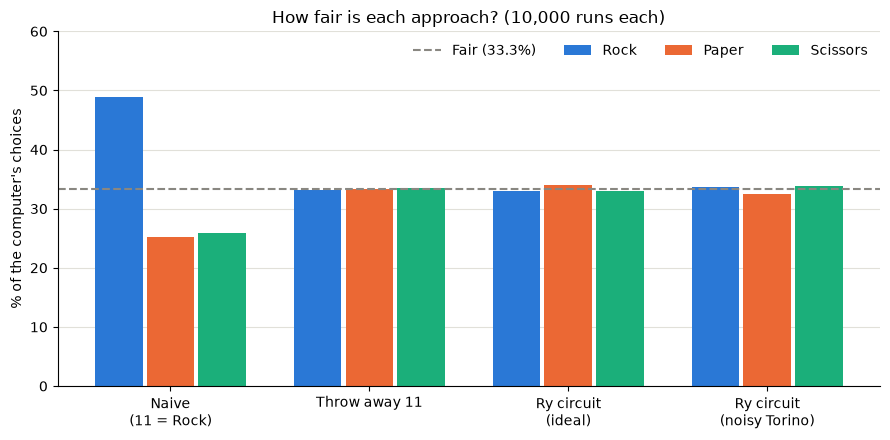

In [13]:
import matplotlib.pyplot as plt

# Rock / Paper / Scissors counts for each approach
naive = {'Rock': counts['00'] + counts['11'], 'Paper': counts['01'], 'Scissors': counts['10']}
exact = {choice_map[b]: n for b, n in counts3.items()}
noisy = {choice_map[b]: n for b, n in counts_noisy.items() if b in choice_map}   # 11s dropped, like the game's safety net

approaches = {
    "Naive\n(11 = Rock)": naive,
    "Throw away 11": tally,
    "Ry circuit\n(ideal)": exact,
    "Ry circuit\n(noisy Torino)": noisy,
}

x = np.arange(len(approaches))
width = 0.26
colors = {'Rock': '#2a78d6', 'Paper': '#eb6834', 'Scissors': '#1baf7a'}

fig, ax = plt.subplots(figsize=(9, 4.5))
for i, choice in enumerate(['Rock', 'Paper', 'Scissors']):
    pcts = [100 * d[choice] / sum(d.values()) for d in approaches.values()]
    ax.bar(x + (i - 1) * width, pcts, width * 0.92, label=choice, color=colors[choice])

ax.axhline(100 / 3, color='#898781', linestyle='--', linewidth=1.5, label='Fair (33.3%)')
ax.set_xticks(x, approaches.keys())
ax.set_ylabel("% of the computer's choices")
ax.set_title("How fair is each approach? (10,000 runs each)")
ax.set_ylim(0, 60)
ax.grid(axis='y', color='#e1e0d9', linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=4, loc='upper right')

plt.tight_layout()
plt.savefig("comparison.png", dpi=150)
plt.show()

## Answers to the deeper questions
1. **How can you make the three choices equally likely?** Throw away `11` and measure again (Approach 2), or build a state with exactly three equal outcomes using `Ry` + controlled-H (Approach 3).
2. **Why is generating three equally probable states more difficult than two?** An H gate splits a qubit 50/50, so n qubits with H gates give 2ⁿ equally likely outcomes: 2, 4, 8, 16… Two outcomes are easy (one qubit and one H gate make a fair coin), but 3 is not a power of 2, so no number of H gates gives exactly three. Two qubits give four, leaving `11` left over. To get three, you either throw results away (wasteful) or design an uneven split: `Ry` gives 2/3 vs 1/3, and a controlled-H divides the 2/3 in half. That takes more gates, and on real hardware more gates means more noise.
3. **What happens if you simply map `11` to one of the choices?** That choice gets two of the four results, so it comes up about 50% of the time (Rock 48.9% in my test).
4. **Could this introduce bias?** Yes. The game becomes predictable: always playing Paper wins about half the games.

## 9. Conclusions & what I learned
- **Superposition + measurement give real randomness**, but small samples look uneven (59/41 with 100 coin flips; Scissors 6 of 11 in my game). It takes many shots (10,000) to judge whether something is fair.
- **Two qubits give 4 outcomes, not 3.** Treating the extra `11` as Rock made the game unfair (Rock ≈ 49%).
- **Throwing away `11` is fair but wasteful**: about 25% of runs were lost.
- **Designing the quantum state directly works best.** `Ry` gives an adjustable split, and a controlled-H acts in only one branch, so each choice gets exactly 1/3 and nothing is wasted.
- **Real hardware is noisy.** The "impossible" `11` appeared 0.7% of the time on the simulated IBM Torino chip and 0.6% on the real ibm_fez, so the simulator predicted the hardware well, and a classical safety net is still needed.

**What surprised me most:** I didn't expect a computer to give a result that should be impossible.

**If I had more time:** I would try error mitigation to reduce the `11` results on hardware, and repeat the hardware run to check whether Rock's extra 1% on ibm_fez is a real bias or just chance.

## AI disclosure
**AI tool:** Claude (Anthropic)

**How I used it:**
- **Learning:** I used Claude as a tutor to understand superposition, measurement, `Ry` rotations, controlled gates and noise, and to choose a challenge that matched what I learned in the workshops.
- **Code:** Claude suggested the code one step at a time and explained it line by line. I ran and tested every cell myself in qBraid, compared the results with what I expected, and played and analysed the game. Claude also guided me through connecting to IBM's real quantum computers.
- **Write-up:** All the results and numbers come from my own runs. Claude helped me word the explanations.
- **Promo video:** I used Claude Code with the brag plugin to make a short video of the project.